#### Import Dependencies

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder

#### Data Exploration

In [33]:
emails_dataset = pd.read_csv('email.csv')
emails_dataset.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [34]:
emails_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5573 entries, 0 to 5572
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5573 non-null   object
 1   Message   5573 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [35]:
emails_dataset.describe()

,Category,Message
count,5573,5573
unique,3,5158
top,ham,"Sorry, I'll call later"
freq,4825,30


In [36]:
emails_dataset['Category'].value_counts()

Category
ham               4825
spam               747
{"mode":"full"       1
Name: count, dtype: int64

In [37]:
emails_dataset['Message'].duplicated().sum()

np.int64(415)

#### Data Cleaning

In [38]:
emails_dataset = emails_dataset[emails_dataset['Category'].isin(['ham', 'spam'])]

In [39]:
emails_dataset

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [40]:
emails_dataset = emails_dataset.drop_duplicates()
emails_dataset

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


#### Data Preprocessing

In [41]:
X = emails_dataset['Message']
y = emails_dataset['Category']

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True, stratify=y
)

In [42]:
encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)

#### Model Training

##### Cross Validation

In [43]:
skf = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

models = {
    'LogisticRegression': LogisticRegression(class_weight='balanced', random_state=42),
    'LinearSVC': LinearSVC(class_weight='balanced'),
    'MultinomialNB': MultinomialNB()
}

scoring={
    'precision': 'precision', 
    'recall': 'recall', 
    'f1': 'f1'
}

In [44]:
rows = []

for name, clf in models.items():
    pipeline = Pipeline(
        [('vectorizer', TfidfVectorizer()),
         (name, clf)]
    )

    cv = cross_validate(
        estimator=pipeline, X=x_train, y=y_train_encoded, scoring=scoring, cv=skf
    )

    rows.append(
        {
            'model': name,
            'precision': cv['test_precision'].mean(),
            'recall': cv['test_recall'].mean(),
            'f1': cv['test_f1'].mean(),
            'f1 std': cv['test_f1'].std()
        }
    )


rows

[{'model': 'LogisticRegression',
  'precision': np.float64(0.9022860762871343),
  'recall': np.float64(0.935655815724348),
  'f1': np.float64(0.9186399220634692),
  'f1 std': np.float64(0.00697366798125308)},
 {'model': 'LinearSVC',
  'precision': np.float64(0.9717015877742448),
  'recall': np.float64(0.9259280411193604),
  'f1': np.float64(0.948101376480747),
  'f1 std': np.float64(0.003966420322875832)},
 {'model': 'MultinomialNB',
  'precision': np.float64(1.0),
  'recall': np.float64(0.5808871121264039),
  'f1': np.float64(0.7331923382741501),
  'f1 std': np.float64(0.0461757772410667)}]

In [45]:
scores_df = pd.DataFrame(data=rows)
scores_df

,model,precision,recall,f1,f1 std
0,LogisticRegression,0.902286,0.935656,0.918640,0.006974
1,LinearSVC,0.971702,0.925928,0.948101,0.003966
2,MultinomialNB,1.000000,0.580887,0.733192,0.046176


##### Fine Tuning

In [46]:
GridParams = {
    'LogisticRegression': {
        'model__C': [0.01, 0.1, 1, 10, 100]
    },
    'LinearSVC':{
        'model__C': [0.01, 0.1, 1, 10, 100],
    },
    'MultinomialNB': {
        'model__alpha': [0.01, 0.03, 0.1, 0.3, 1]
    },
}

In [47]:
best = []

for name, clf in models.items():
    pipeline = Pipeline(
        [('vectorizer', TfidfVectorizer()),
         ('model', clf)]
    )

    grid = GridSearchCV(
        estimator=pipeline, param_grid=GridParams[name], 
        scoring='f1', verbose=2, n_jobs= -1,
        cv=skf, return_train_score=True
    )


    grid.fit(x_train, y_train_encoded)

    best.append(
        {
            'model_name': name,
            'best_params': grid.best_params_,
            'best_estimator': grid.best_estimator_,
            'best_score': grid.best_score_
        }
    )

print(best)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Fitting 5 folds for each of 5 candidates, totalling 25 fits
[{'model_name': 'LogisticRegression', 'best_params': {'model__C': 100}, 'best_estimator': Pipeline(steps=[('vectorizer', TfidfVectorizer()),
                ('model',
                 LogisticRegression(C=100, class_weight='balanced',
                                    random_state=42))]), 'best_score': np.float64(0.9396245564153972)}, {'model_name': 'LinearSVC', 'best_params': {'model__C': 10}, 'best_estimator': Pipeline(steps=[('vectorizer', TfidfVectorizer()),
                ('model', LinearSVC(C=10, class_weight='balanced'))]), 'best_score': np.float64(0.9486042197979302)}, {'model_name': 'MultinomialNB', 'best_params': {'model__alpha': 0.03}, 'best_estimator': Pipeline(steps=[('vectorizer', TfidfVectorizer()),
                ('model', MultinomialNB(alpha=0.03))]), 'best_score': np.float64(0.9396643515

In [48]:
best_df = pd.DataFrame(data=best)
best_df

,model_name,best_params,best_estimator,best_score
0,LogisticRegression,{'model__C': 100},"(TfidfVectorizer(), LogisticRegression(C=100, ...",0.939625
1,LinearSVC,{'model__C': 10},"(TfidfVectorizer(), LinearSVC(C=10, class_weig...",0.948604
2,MultinomialNB,{'model__alpha': 0.03},"(TfidfVectorizer(), MultinomialNB(alpha=0.03))",0.939664


In [49]:
y_test_encoded = encoder.transform(y_test)

In [50]:
best_df['best_score'].idxmax()

1

In [51]:
winner = best_df.loc[best_df['best_score'].idxmax()]
winner

model_name                                                LinearSVC
best_params                                        {'model__C': 10}
best_estimator    (TfidfVectorizer(), LinearSVC(C=10, class_weig...
best_score                                                 0.948604
Name: 1, dtype: object

In [52]:
final_model = winner['best_estimator']
final_model

,steps,"[('vectorizer', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


In [53]:
y_pred = final_model.predict(x_test)

In [54]:
print(classification_report(y_true=y_test_encoded, y_pred=y_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       904
           1       0.96      0.85      0.90       128

    accuracy                           0.98      1032
   macro avg       0.97      0.92      0.94      1032
weighted avg       0.98      0.98      0.98      1032



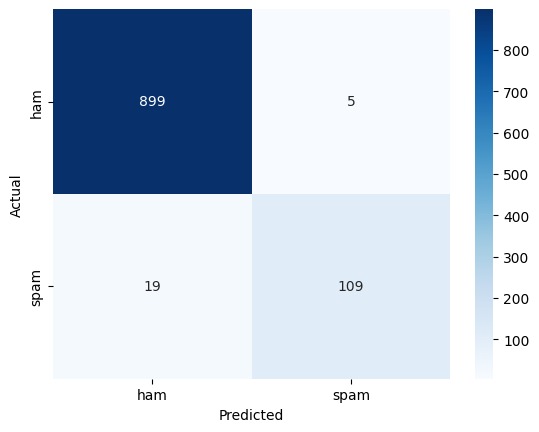

In [57]:
cm = confusion_matrix(y_test_encoded, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()